# 4-class ablation: LLM augmentation only, no class weighting, no translated CN

This notebook keeps the same clean 4-class split and train-source-only LLM augmentation pipeline, but removes class weighting and translated CN data.


In [1]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [4]:
# =========================
# CONFIG
# =========================
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"
#AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2.csv"
AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2_4class.csv"
TRANSLATED_CN_PATH = "/content/drive/MyDrive/conversation_cn_translated_en_deepseek_v4flash.json"

RESULTS_DIR = "/content/drive/MyDrive/intent9Aug/4class_ablation_B_only_LLM_noCW_noCN"
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_LEN = 256
RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5

VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise"]
label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3}
id2label = {v: k for k, v in label2id.items()}

print("Labels:", label2id)
print("LR:", LEARNING_RATE, "weight_decay:", WEIGHT_DECAY)
print("Ablation setup: B only = LLM synthetic augmentation YES, class weighting NO, translated CN NO")


Labels: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3}
LR: 2e-05 weight_decay: 0.01
Ablation setup: B only = LLM synthetic augmentation YES, class weighting NO, translated CN NO


In [5]:
# =========================
# LOAD ORIGINAL ENGLISH DATA
# =========================
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Original full turn rows:", len(df_turns_full))
print("Original 4-class target rows:", len(target_df))
print("Original conversations:", target_df["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Original full turn rows: 5633
Original 4-class target rows: 3179
Original conversations: 825
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [6]:
# =========================
#  GROUPED SINGLE SPLIT
# =========================
gss1 = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(
    n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df_original = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

train_cids = set(train_df_original["conversation_id"].astype(str))
val_cids = set(val_df["conversation_id"].astype(str))
test_cids = set(test_df["conversation_id"].astype(str))

print("Original train rows:", len(train_df_original))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("Train ∩ Val:", len(train_cids & val_cids))
print("Train ∩ Test:", len(train_cids & test_cids))
print("Val ∩ Test:", len(val_cids & test_cids))

assert train_cids.isdisjoint(val_cids)
assert train_cids.isdisjoint(test_cids)
assert val_cids.isdisjoint(test_cids)

#4class original english data split
assert len(train_df_original) == 2014, f"Unexpected train rows: {len(train_df_original)}"
assert len(val_df) == 503, f"Unexpected val rows: {len(val_df)}"
assert len(test_df) == 662, f"Unexpected test rows: {len(test_df)}"



Original train rows: 2014
Validation rows: 503
Test rows: 662
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [7]:
# =========================
# LLM AUGMENTATION TRAIN DATA ONLY
# =========================
aug_all_df = pd.read_csv(AUGMENTED_TRAIN_PATH)

required_aug_columns = {
    "conversation_id", "turn_index", "role", "text", "intent", "is_augmented"
}
missing_columns = required_aug_columns - set(aug_all_df.columns)
assert not missing_columns, f"Missing augmentation columns: {missing_columns}"

aug_all_df["conversation_id"] = aug_all_df["conversation_id"].astype(str)
aug_all_df["turn_index"] = pd.to_numeric(
    aug_all_df["turn_index"], errors="raise"
).astype(int)
aug_all_df["role"] = (
    aug_all_df["role"].fillna("").astype(str).str.strip().str.lower()
)
aug_all_df["text"] = aug_all_df["text"].fillna("").astype(str)
aug_all_df["intent"] = (
    aug_all_df["intent"].fillna("").astype(str).str.strip()
)

is_genuine_augmentation = (
    aug_all_df["is_augmented"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "1.0"])
)

aug_genuine_df = aug_all_df[
    is_genuine_augmentation
    & (aug_all_df["role"] == "user")
    & (aug_all_df["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

assert len(aug_genuine_df) > 0, (
    "No genuine augmented rows found. Check the is_augmented column."
)

#synthetic row may enter training only if its source English conversation is in the original train data
aug_train_df = aug_genuine_df[
    aug_genuine_df["conversation_id"].isin(train_cids)
].copy().reset_index(drop=True)

aug_cids = set(aug_train_df["conversation_id"].astype(str))

print("Rows in augmentation CSV:", len(aug_all_df))
print("Original/non-augmented rows excluded:", int((~is_genuine_augmentation).sum()))
print("valid 4-class augmentation rows:", len(aug_genuine_df))
print("Train-source genuine augmentation kept:", len(aug_train_df))
print("Valid augmentation rows excluded because source was not TRAIN:",
    len(aug_genuine_df) - len(aug_train_df),
)
print("Aug source ∩ Val:", len(aug_cids & val_cids))
print("Aug source ∩ Test:", len(aug_cids & test_cids))
print("Aug source outside Train:", len(aug_cids - train_cids))

assert aug_cids.isdisjoint(val_cids), (
    "LEAKAGE: validation-source augmentation entered training."
)
assert aug_cids.isdisjoint(test_cids), (
    "LEAKAGE: test-source augmentation entered training."
)
assert aug_cids.issubset(train_cids), (
    "Unexpected augmentation source outside original training split."
)

# Verify every synthetic row maps to an original 4-class TRAIN source turn
source_4class = train_df_original[
    ["conversation_id", "turn_index", "intent"]
].copy()
source_4class["conversation_id"] = source_4class["conversation_id"].astype(str)
source_4class["turn_index"] = source_4class["turn_index"].astype(int)

aug_source_check = aug_train_df.merge(
    source_4class,
    on=["conversation_id", "turn_index"],
    how="left",
    suffixes=("_aug", "_source"),
)

missing_source_turns = int(aug_source_check["intent_source"].isna().sum())
changed_labels = int((
    aug_source_check["intent_source"].notna()
    & (aug_source_check["intent_aug"] != aug_source_check["intent_source"])
).sum())

print("Augmented rows missing original TRAIN source turn:", missing_source_turns)
print("Augmented rows with changed labels:", changed_labels)

assert missing_source_turns == 0
assert changed_labels == 0

Rows in augmentation CSV: 2214
Original/non-augmented rows excluded: 2014
valid 4-class augmentation rows: 200
Train-source genuine augmentation kept: 200
Valid augmentation rows excluded because source was not TRAIN: 0
Aug source ∩ Val: 0
Aug source ∩ Test: 0
Aug source outside Train: 0
Augmented rows missing original TRAIN source turn: 0
Augmented rows with changed labels: 0


In [8]:
# =========================
# TRANSLATED CHINESE DATA DISABLED FOR THIS ABLATION
# =========================
# Ablation condition B only:
#   Class weighting: No
#   Synthetic augmentation: Yes
#   Translated data: No

cn_train_df = pd.DataFrame(columns=train_df_original.columns)

print("Translated CN disabled for this ablation.")
print("CN rows retained:", len(cn_train_df))


Translated CN disabled for this ablation.
CN rows retained: 0


In [9]:
# =========================
# FINAL TRAIN + LEAKAGE AUDIT
# =========================
# B-only ablation: original English train + safe LLM augmentation only.
# No translated CN data is added.
train_df = pd.concat(
    [train_df_original, aug_train_df],
    ignore_index=True,
).reset_index(drop=True)

print("Final train rows:", len(train_df))
print("  original English:", len(train_df_original))
print("  genuine safe augmentation:", len(aug_train_df))
print("  translated CN:", 0)
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("\nFinal train label distribution:")
print(train_df["intent"].value_counts())

missing_context_cids = (
    set(train_df["conversation_id"].astype(str)) - set(turns_by_conv_full.keys())
)
print("Missing context conversation IDs:", len(missing_context_cids))
assert len(missing_context_cids) == 0

# Exact text overlap is diagnostic only. Independent conversations may contain
# identical short utterances; source-conversation isolation is the leakage rule.
def norm_text(x):
    x = str(x).lower().strip()
    x = re.sub(r"\s+", " ", x)
    return x

train_texts = set(train_df["text"].map(norm_text)) - {""}
val_texts = set(val_df["text"].map(norm_text)) - {""}
test_texts = set(test_df["text"].map(norm_text)) - {""}
print("Exact target-text overlap train/val (diagnostic):", len(train_texts & val_texts))
print("Exact target-text overlap train/test (diagnostic):", len(train_texts & test_texts))

audit = pd.DataFrame([{
    "ablation_setup": "B only: LLM augmentation yes, class weighting no, translated CN no",
    "original_train_rows": len(train_df_original),
    "augmentation_csv_rows": len(aug_all_df),
    "genuine_4class_aug_rows": len(aug_genuine_df),
    "safe_train_source_aug_rows": len(aug_train_df),
    "genuine_aug_rows_excluded_nontrain_source": len(aug_genuine_df) - len(aug_train_df),
    "translated_cn_rows": 0,
    "final_train_rows": len(train_df),
    "val_rows": len(val_df),
    "test_rows": len(test_df),
    "train_val_cid_overlap": len(train_cids & val_cids),
    "train_test_cid_overlap": len(train_cids & test_cids),
    "val_test_cid_overlap": len(val_cids & test_cids),
    "aug_val_source_overlap": len(aug_cids & val_cids),
    "aug_test_source_overlap": len(aug_cids & test_cids),
    "aug_missing_source_turns": missing_source_turns,
    "aug_changed_labels": changed_labels,
}])

audit.to_csv(os.path.join(RESULTS_DIR, "leakage_audit_B_only_noCW_noCN.csv"), index=False)
display(audit)

assert len(train_cids & val_cids) == 0
assert len(train_cids & test_cids) == 0
assert len(val_cids & test_cids) == 0
assert len(aug_cids & val_cids) == 0
assert len(aug_cids & test_cids) == 0
assert missing_source_turns == 0
assert changed_labels == 0

print("PASS: no conversation-ID or source-provenance overlap detected.")


Final train rows: 2214
  original English: 2014
  genuine safe augmentation: 200
  translated CN: 0
Validation rows: 503
Test rows: 662

Final train label distribution:
intent
Interpret    1130
Reveal        673
Chitchat      276
Revise        135
Name: count, dtype: int64
Missing context conversation IDs: 0
Exact target-text overlap train/val (diagnostic): 48
Exact target-text overlap train/test (diagnostic): 56


,ablation_setup,original_train_rows,augmentation_csv_rows,genuine_4class_aug_rows,safe_train_source_aug_rows,genuine_aug_rows_excluded_nontrain_source,translated_cn_rows,final_train_rows,val_rows,test_rows,train_val_cid_overlap,train_test_cid_overlap,val_test_cid_overlap,aug_val_source_overlap,aug_test_source_overlap,aug_missing_source_turns,aug_changed_labels
0,"B only: LLM augmentation yes, class weighting ...",2014,2214,200,200,0,0,2214,503,662,0,0,0,0,0,0,0


PASS: no conversation-ID or source-provenance overlap detected.


In [11]:
 #context builder

def build_context_dataset(df_split, turns_by_conv):
    X, y = [], []
    for _, row in df_split.iterrows():
        cid = str(row["conversation_id"])
        ti = int(row["turn_index"])
        conv_turns = turns_by_conv[cid]
        prev_turns = conv_turns[conv_turns["turn_index"] < ti]

        history = []
        for _, p in prev_turns.iterrows():
            role = str(p["role"]).upper().strip()
            text = str(p["text"]).strip()
            if text:
                history.append(f"{role}: {text}")

        current_turn = str(row["text"]).strip()
        full_text = ("\n".join(history) + "\n" if history else "") + f"USER: {current_turn}"
        X.append(full_text)
        y.append(row["intent"])
    return np.array(X), np.array(y)

X_train, y_train = build_context_dataset(train_df, turns_by_conv_full)
X_val, y_val = build_context_dataset(val_df, turns_by_conv_full)
X_test, y_test = build_context_dataset(test_df, turns_by_conv_full)

print("Context-aware train:", len(X_train))
print("Context-aware val:", len(X_val))
print("Context-aware test:", len(X_test))
print("\nTest distribution:\n", pd.Series(y_test).value_counts())

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nVal distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# Optional sanity check
revise_indices = [i for i, l in enumerate(y_train) if l == "Revise"]
if revise_indices:
    print("\n--- Sample Revise context (verify SYSTEM turn is present) ---")
    for line in X_train[revise_indices[0]].split("\n"):
        print(" ", line[:110])

Context-aware train: 2214
Context-aware val: 503
Context-aware test: 662

Test distribution:
 Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

Train distribution:
Interpret    1130
Reveal        673
Chitchat      276
Revise        135
Name: count, dtype: int64

Val distribution:
Interpret    292
Reveal       161
Chitchat      38
Revise        12
Name: count, dtype: int64

Test distribution:
Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

--- Sample Revise context (verify SYSTEM turn is present) ---
  USER: hello，I want buy a mug
  SYSTEM: how about these？
  USER: ok,the first one i will choose.


In [12]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))


--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [13]:
print(X_train[1])

USER: Hello, I want a Cotton mops.
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [14]:
# =========================
# LABEL IDS + DISTRIBUTION
# =========================
# Class weighting is intentionally disabled for this ablation.
y_train_ids = np.array([label2id[x] for x in y_train], dtype=np.int64)
y_val_ids   = np.array([label2id[x] for x in y_val], dtype=np.int64)
y_test_ids  = np.array([label2id[x] for x in y_test], dtype=np.int64)

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist,
}).reindex(VALID_LABELS).fillna(0)

print("Label distribution (%):")
print(dist_df)

classes = np.arange(len(VALID_LABELS))
missing = set(classes) - set(np.unique(y_train_ids))
assert not missing, f"Missing train classes: {[id2label[i] for i in sorted(missing)]}"

USE_CLASS_WEIGHTS = False
print("\nClass weighting enabled:", USE_CLASS_WEIGHTS)


Label distribution (%):
            train_%     val_%    test_%
Chitchat   0.124661  0.075547  0.081571
Interpret  0.510388  0.580517  0.590634
Reveal     0.303975  0.320080  0.297583
Revise     0.060976  0.023857  0.030211

Class weighting enabled: False


In [15]:
# ── Standard Trainer + metrics ──────────────────────────────
# No class-weighted loss is used in this ablation.
from transformers import Trainer
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        labels=np.arange(len(VALID_LABELS)),
        average="macro",
        zero_division=0,
    )

    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("Standard Trainer and compute_metrics defined. Class weights are OFF.")


Standard Trainer and compute_metrics defined. Class weights are OFF.


In [16]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

In [17]:
# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)

    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        digits=3,
        zero_division=0,
    )

    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)

    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )

    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    # Compact numeric metrics for paper tables
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="macro",
        zero_division=0,
    )

    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="weighted",
        zero_division=0,
    )

    acc = accuracy_score(y_true, y_pred)

    _, _, per_class_f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average=None,
        zero_division=0,
    )

    metrics = {
        "split": split_name.upper(),
        "model": model_name,
        "accuracy": acc,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_p,
        "weighted_recall": weighted_r,
        "weighted_f1": weighted_f1,
        "samples": len(y_true),
    }

    for label, f1_val, supp in zip(VALID_LABELS, per_class_f1, support):
        metrics[f"{label.lower()}_f1"] = f1_val
        metrics[f"{label.lower()}_support"] = supp

    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"

    # Save confusion matrix image
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS,
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULTS_DIR, f"{tag}_cm.png"),
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    # Save predictions
    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred,
    })

    pred_df.to_csv(
        os.path.join(RESULTS_DIR, f"{tag}_predictions.csv"),
        index=False,
    )

    # Misclassified examples
    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]

    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:

        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_misclassified.csv"),
            index=False,
        )

        confused_pairs.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_confused_pairs.csv"),
            index=False,
        )

    # Save text report
    with open(
        os.path.join(RESULTS_DIR, f"{tag}_report.txt"),
        "w",
        encoding="utf-8",
    ) as f:

        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)

        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        f.write("\n\n=== COMPACT METRICS ===\n")
        f.write(pd.DataFrame([metrics]).to_string(index=False))

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))

            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors, metrics


print("All helpers defined.")

All helpers defined.


In [18]:
# ── Master helper: train one model end-to-end ────────────────
def run_model(model_name, num_epochs=NUM_EPOCHS):
    """
    1. Tokenize with the model's own tokenizer.
    2. Train with standard Trainer using TRAIN data, without class weighting.
    3. Select best checkpoint using VAL macro-F1.
    4. Plot learning curve.
    5. Evaluate on TRAIN, VAL, and TEST.
    """
    print("\n" + "=" * 65)
    print(f"  MODEL: {model_name}")
    print("=" * 65)

    set_seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    torch.manual_seed(RANDOM_STATE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_STATE)

    # DeBERTa-v3 needs sentencepiece; use_fast=False avoids tokenizer issues
    use_fast = False if "deberta-v3" in model_name else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train,
        y_train_ids,
        X_val,
        y_val_ids,
        X_test,
        y_test_ids,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id,
    )

    short_name = model_name.split("/")[-1]
    output_dir = os.path.join(RESULTS_DIR, f"{short_name}_results")

    training_args = TrainingArguments(
        output_dir=output_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=torch.cuda.is_available() and "deberta-v3" not in model_name,
        save_total_limit=2,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    print("Best checkpoint:", trainer.state.best_model_checkpoint)
    print("Best validation macro-F1:", trainer.state.best_metric)

    # Learning curve based on validation metrics
    plot_learning_curve(trainer, short_name)

    # Train evaluation
    _, _, _, _, train_metrics = evaluate_and_report(
        trainer,
        train_ds,
        y_train_ids,
        X_train,
        split_name="TRAIN",
        model_name=short_name,
    )

    # Validation evaluation
    _, _, _, _, val_metrics = evaluate_and_report(
        trainer,
        val_ds,
        y_val_ids,
        X_val,
        split_name="VAL",
        model_name=short_name,
    )

    # Final unbiased test evaluation
    _, _, _, _, test_metrics = evaluate_and_report(
        trainer,
        test_ds,
        y_test_ids,
        X_test,
        split_name="TEST",
        model_name=short_name,
    )

    all_metrics_df = pd.DataFrame([train_metrics, val_metrics, test_metrics])
    all_metrics_path = os.path.join(
        RESULTS_DIR,
        f"{short_name}_all_split_metrics.csv",
    )
    all_metrics_df.to_csv(all_metrics_path, index=False)

    print("\n=== Compact metrics summary ===")
    display(all_metrics_df)
    print(f"Saved metrics summary: {all_metrics_path}")

    return trainer, test_metrics


print("run_model() defined for B-only ablation: LLM yes, class weights no, CN no.")

run_model() defined for B-only ablation: LLM yes, class weights no, CN no.


## BERT-base only


In [19]:
# DistilBERT disabled for this B-only ablation notebook.


## RoBERTa disabled


In [20]:
# RoBERTa disabled for this B-only ablation notebook.


## BERT-base-uncased



  MODEL: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint: /content/drive/MyDrive/intent9Aug/4class_ablation_B_only_LLM_noCW_noCN/bert-base-uncased_results/checkpoint-1385
Best validation macro-F1: 0.7029254383209758


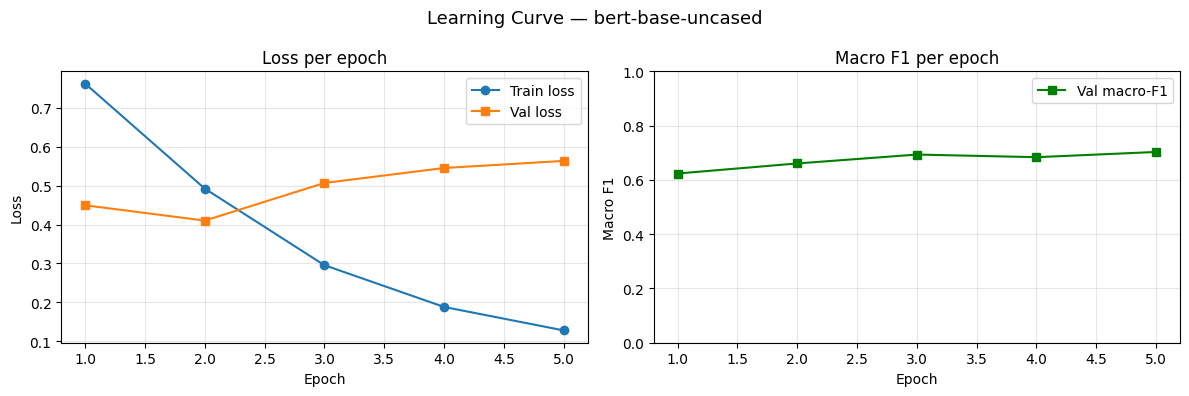

Saved: bert-base-uncased_learning_curve.png



=== bert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.932     0.938     0.935       276
   Interpret      0.989     0.991     0.990      1130
      Reveal      0.975     0.967     0.971       673
      Revise      0.985     0.985     0.985       135

    accuracy                          0.977      2214
   macro avg      0.970     0.971     0.970      2214
weighted avg      0.977     0.977     0.977      2214


=== bert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             259               5           10            2
true_Interpret              5            1120            5            0
true_Reveal                14               8          651            0
true_Revise                 0               0            2          133


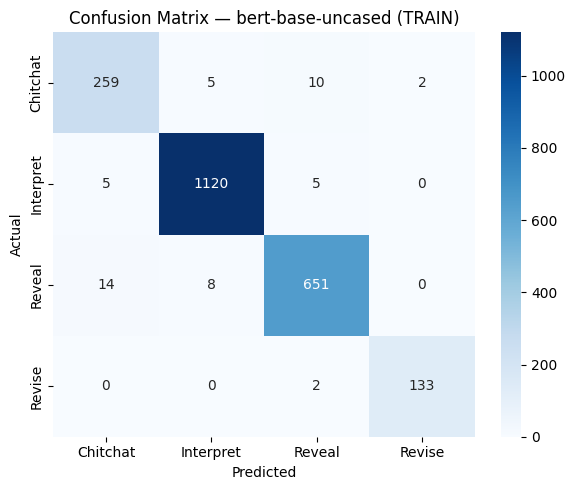


=== bert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.725     0.763     0.744        38
   Interpret      0.894     0.928     0.911       292
      Reveal      0.880     0.863     0.871       161
      Revise      1.000     0.167     0.286        12

    accuracy                          0.877       503
   macro avg      0.875     0.680     0.703       503
weighted avg      0.879     0.877     0.871       503


=== bert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              29               6            3            0
true_Interpret              7             271           14            0
true_Reveal                 4              18          139            0
true_Revise                 0               8            2            2


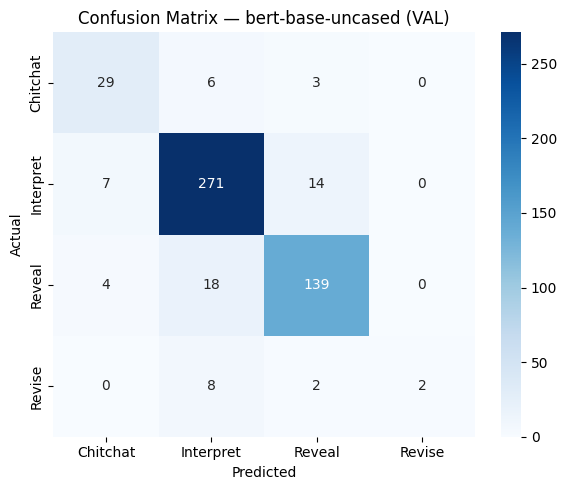


=== bert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,18
1,Interpret,Reveal,14
2,Revise,Interpret,8
3,Interpret,Chitchat,7
4,Chitchat,Interpret,6
5,Reveal,Chitchat,4
6,Chitchat,Reveal,3
7,Revise,Reveal,2



=== bert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Interpret
6,USER: I want to buy a bicycle\nSYSTEM: How abo...,Interpret,Chitchat
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Chitchat
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
32,USER: hello!\nSYSTEM: hi\nUSER: I wanna a phot...,Interpret,Chitchat
37,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat



=== bert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.860     0.685     0.763        54
   Interpret      0.866     0.941     0.902       391
      Reveal      0.853     0.822     0.837       197
      Revise      0.250     0.050     0.083        20

    accuracy                          0.858       662
   macro avg      0.707     0.625     0.646       662
weighted avg      0.843     0.858     0.847       662


=== bert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              37              11            6            0
true_Interpret              4             368           17            2
true_Reveal                 2              32          162            1
true_Revise                 0              14            5            1


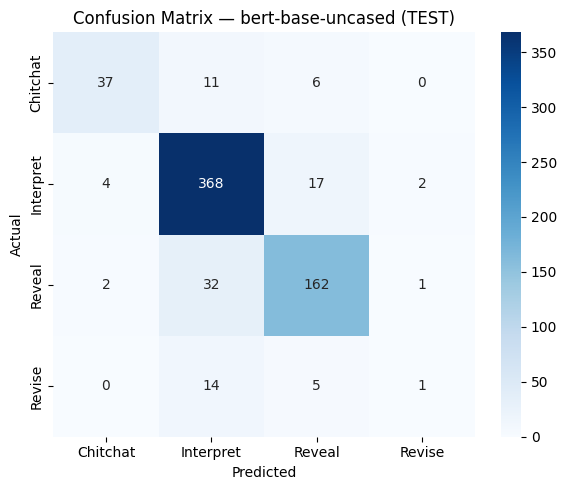


=== bert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,32
1,Interpret,Reveal,17
2,Revise,Interpret,14
3,Chitchat,Interpret,11
4,Chitchat,Reveal,6
5,Revise,Reveal,5
6,Interpret,Chitchat,4
7,Interpret,Revise,2
8,Reveal,Chitchat,2
9,Reveal,Revise,1



=== bert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Reveal
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
32,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Reveal
38,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
39,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret



=== Compact metrics summary ===


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,samples,chitchat_f1,chitchat_support,interpret_f1,interpret_support,reveal_f1,reveal_support,revise_f1,revise_support
0,TRAIN,bert-base-uncased,0.976965,0.969979,0.970513,0.970239,0.976985,0.976965,0.976968,2214,0.935018,276,0.989837,1130,0.970917,673,0.985185,135
1,VAL,bert-base-uncased,0.876740,0.874784,0.680315,0.702925,0.879425,0.876740,0.870740,503,0.743590,38,0.910924,292,0.871473,161,0.285714,12
2,TEST,bert-base-uncased,0.858006,0.707245,0.624674,0.646348,0.842891,0.858006,0.846615,662,0.762887,54,0.901961,391,0.837209,197,0.083333,20


Saved metrics summary: /content/drive/MyDrive/intent9Aug/4class_ablation_B_only_LLM_noCW_noCN/bert-base-uncased_all_split_metrics.csv


,Setup,Class_weighting,Synthetic_augmentation,Translated_data,Model,Seed,Accuracy,Macro_F1,Weighted_F1,Chitchat_F1,Interpret_F1,Reveal_F1,Revise_F1,Test_samples
0,B only,No,Yes,No,BERT-base,42,0.858006,0.646348,0.846615,0.762887,0.901961,0.837209,0.083333,662


Saved manuscript-ready B-only ablation row.


In [21]:
bert_trainer, bert_test_metrics = run_model("bert-base-uncased", num_epochs=NUM_EPOCHS)

# Save one manuscript-ready row for the ablation table.
ablation_result = pd.DataFrame([{
    "Setup": "B only",
    "Class_weighting": "No",
    "Synthetic_augmentation": "Yes",
    "Translated_data": "No",
    "Model": "BERT-base",
    "Seed": RANDOM_STATE,
    "Accuracy": bert_test_metrics["accuracy"],
    "Macro_F1": bert_test_metrics["macro_f1"],
    "Weighted_F1": bert_test_metrics["weighted_f1"],
    "Chitchat_F1": bert_test_metrics.get("chitchat_f1"),
    "Interpret_F1": bert_test_metrics.get("interpret_f1"),
    "Reveal_F1": bert_test_metrics.get("reveal_f1"),
    "Revise_F1": bert_test_metrics.get("revise_f1"),
    "Test_samples": bert_test_metrics["samples"],
}])

display(ablation_result)
ablation_result.to_csv(
    os.path.join(RESULTS_DIR, "ablation_B_only_LLM_noCW_noCN_BERT_result.csv"),
    index=False,
)
print("Saved manuscript-ready B-only ablation row.")


## MiniLM disabled


In [22]:
# MiniLM disabled for this B-only ablation notebook.


## DeBERTa disabled


In [23]:
# DeBERTa disabled for this B-only ablation notebook.


In [24]:
# DeBERTa run disabled for this B-only ablation notebook.


**Optional BERT inference check**


In [25]:
if isinstance(bert_trainer, tuple):
    bert_trainer = bert_trainer[0]
print(type(bert_trainer))


<class 'transformers.trainer.Trainer'>


In [26]:
import time
import pandas as pd

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased", use_fast=True)

_, _, test_ds_for_model = make_hf_datasets(
    tokenizer,
    X_train, y_train_ids,
    X_val, y_val_ids,
    X_test, y_test_ids,
)

start = time.time()
_ = bert_trainer.predict(test_ds_for_model)
end = time.time()

total_time = end - start
avg_time = total_time / len(X_test)

runtime_df = pd.DataFrame([{
    "model": "BERT Base",
    "hf_model_name": "bert-base-uncased",
    "setup": "B only: LLM yes, class weighting no, CN no",
    "test_samples": len(X_test),
    "total_inference_sec": round(total_time, 3),
    "avg_inference_per_sample_sec": round(avg_time, 5),
}])

display(runtime_df)

runtime_df.to_csv(
    os.path.join(RESULTS_DIR, "bert_B_only_inference_runtime.csv"),
    index=False,
)


,model,hf_model_name,setup,test_samples,total_inference_sec,avg_inference_per_sample_sec
0,BERT Base,bert-base-uncased,"B only: LLM yes, class weighting no, CN no",662,1.454,0.0022
